# Style-based WGAN-GP with Adaptive Discriminator Augmentation

In [1]:
cd ..

d:\Personal Projects\picasso


d:\Personal Projects\picasso\.venv\lib\site-packages\IPython\core\magics\osm.py:417: UserWarning: This is now an optional IPython functionality, setting dhist requires you to install the `pickleshare` library.
  self.shell.db['dhist'] = compress_dhist(dhist)[-100:]


In [2]:
import numpy as np
import matplotlib.pyplot as plt
import torchvision.utils as vutils
from IPython.display import Image as IPImage, display

%matplotlib inline

from picasso.trainers.stylegan_trainer import StyleWGANTrainer, StyleWGANHparams, device
from picasso.models.augment import AugmentPipe
print("Device:", device)

Device: cpu


## Configure and build the trainer
Leave `datapath=None` to auto-find `datasets/Event/Event`. Set `load_from_checkpoint=True` to resume.

- `image_size` must be a power of two (64, 128, 256, ...). Lower `batch_size` / `ngf` / `ndf` if memory is tight.
- `ada=True` adapts the augmentation probability `p` automatically from a small held-out split; set `ada=False` and `ada_p_init=0` to turn augmentation off.

In [3]:
hparams = vars(StyleWGANHparams(
    image_size=64,
    nz=256,
    ngf=32,
    ndf=32,
    n_critic=1,
    lr=0.001,
    ada=True,
))

trainer = StyleWGANTrainer(
    hparams=hparams,
    datapath="./datasets/art-nouveau",
    batch_size=16,
    ckpt_path="./checkpoints/stylewgan_ckpt.pt",
    sample_dir="samples",
    load_from_checkpoint=True,
)
n_g = sum(p.numel() for p in trainer.netG.parameters()) / 1e6
n_c = sum(p.numel() for p in trainer.critic.parameters()) / 1e6
print(f"Generator: {n_g:.1f}M params | Critic: {n_c:.1f}M params")

There are 4845 samples in the data, 4603 training samples and 242 validation samples
Loading checkpoint from ./checkpoints/stylewgan_ckpt.pt...
Loading the models...<All keys matched successfully>
Generator: 5.7M params | Critic: 5.6M params


## Training images and what ADA does to them

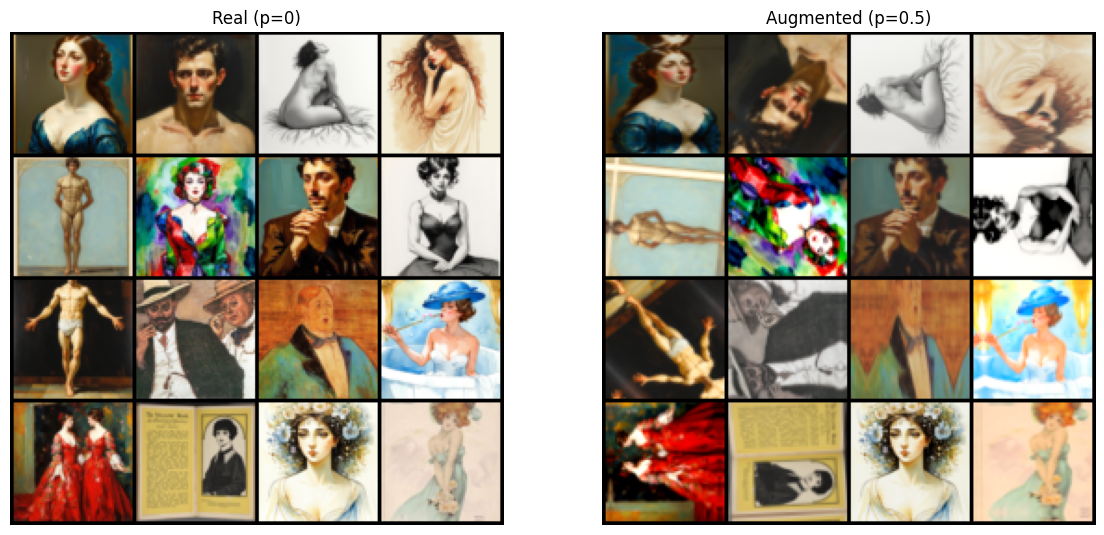

In [4]:
real_batch = next(iter(trainer.train_dl))[0][:16].to(device)
pipe = AugmentPipe(p=0.5)

fig, axes = plt.subplots(1, 2, figsize=(14, 7))
for ax, title, imgs in zip(axes, ["Real (p=0)", "Augmented (p=0.5)"], [real_batch, pipe(real_batch)]):
    ax.axis("off")
    ax.set_title(title)
    ax.imshow(np.transpose(vutils.make_grid(imgs.clamp(-1, 1).cpu(), nrow=4, padding=2, normalize=True), (1, 2, 0)))
plt.show()

## Train
A checkpoint and a sample grid (from the EMA generator) are saved after every epoch. Interrupting the cell still checkpoints.

In [6]:
G_epoch_losses, W_epoch_dists = trainer.fit(
    epochs=50,
    ckpt_path="./checkpoints/stylewgan_ckpt_out.pt",
)

Beginning training...
2026-10-08 20:30


Training Epoch: 1/50:   0%|          | 0/50 [00:00<?, ?it/s]

[1/50][0/287]	Loss_C: 10.3851	W-dist: -1.3253	GP: 0.9060	D(x): 0.431	D(G(z)): 1.757	p: 0.000	r_v: nan


Training Epoch: 1/50:   0%|          | 0/50 [00:58<?, ?it/s]


Checkpointing...
Done
2026-10-08 20:31


## Training curves

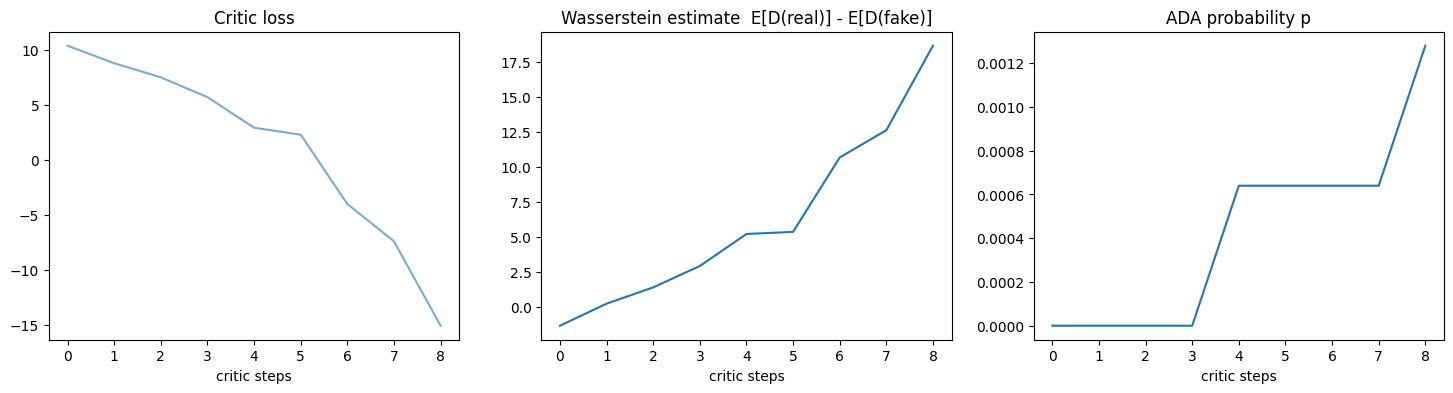

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
axes[0].plot(trainer.C_losses, alpha=0.6)
axes[0].set_title("Critic loss")
axes[1].plot(trainer.w_dists)
axes[1].set_title("Wasserstein estimate  E[D(real)] - E[D(fake)]")
axes[2].plot(trainer.ada_ps)
axes[2].set_title("ADA probability p")
for ax in axes:
    ax.set_xlabel("critic steps")
plt.show()

## Real vs. generated

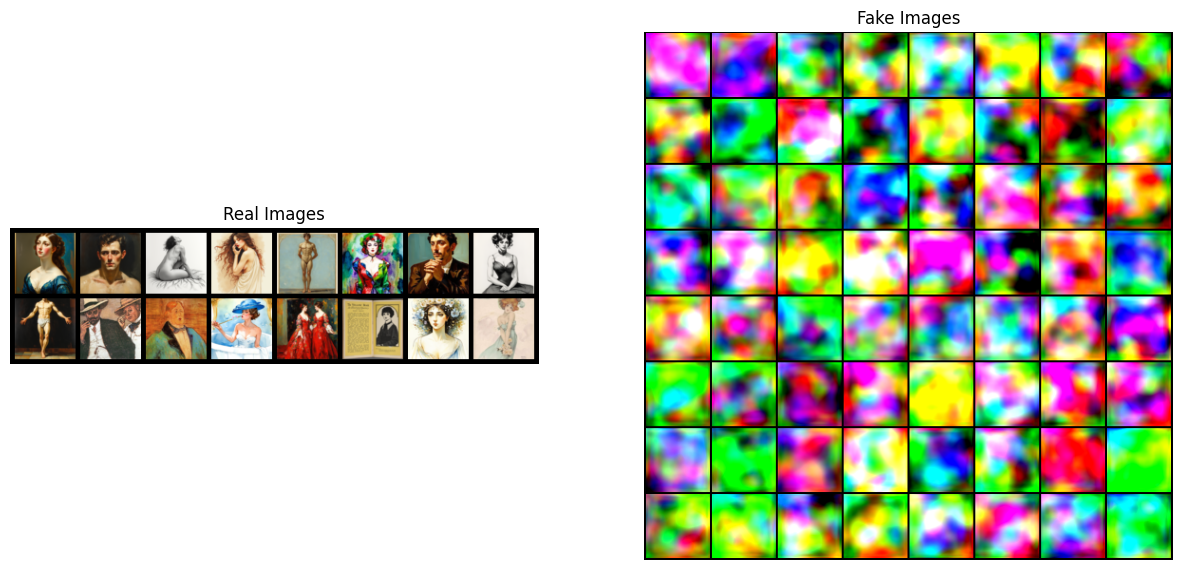

In [11]:
fake = trainer.generate(64)

plt.figure(figsize=(15, 15))
plt.subplot(1, 2, 1)
plt.axis("off")
plt.title("Real Images")
plt.imshow(np.transpose(vutils.make_grid(real_batch.cpu(), padding=5, normalize=True), (1, 2, 0)))

plt.subplot(1, 2, 2)
plt.axis("off")
plt.title("Fake Images")
plt.imshow(np.transpose(vutils.make_grid(fake, padding=2, normalize=True, value_range=(-1, 1)), (1, 2, 0)))
plt.show()

## Truncation trick
Lower `truncation_psi` gives cleaner but less varied images.

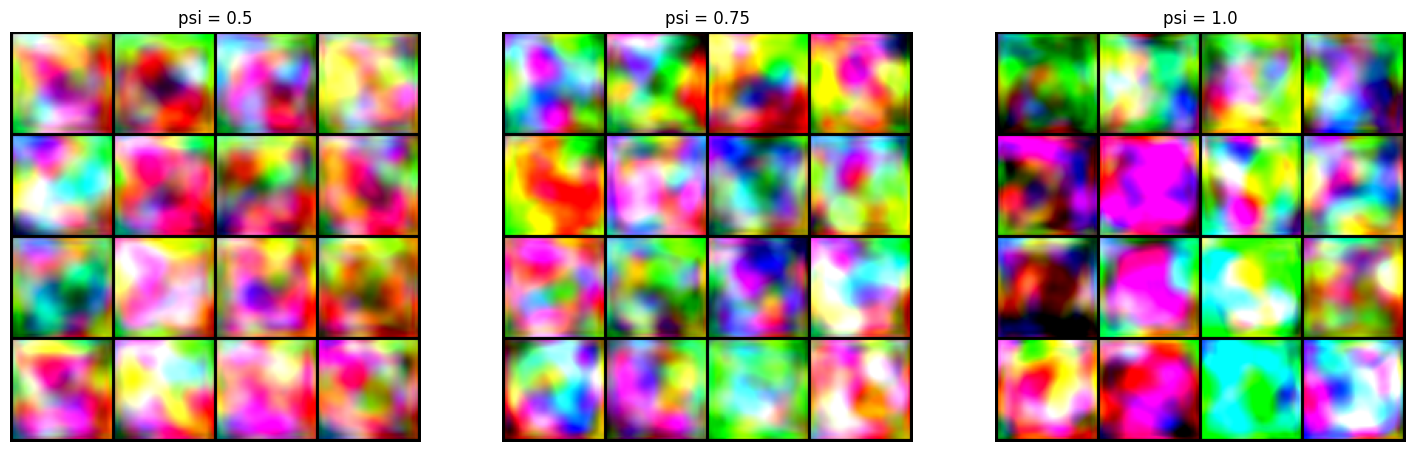

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, psi in zip(axes, [0.5, 0.75, 1.0]):
    imgs = trainer.generate(16, truncation_psi=psi)
    ax.axis("off")
    ax.set_title(f"psi = {psi}")
    ax.imshow(np.transpose(vutils.make_grid(imgs, nrow=4, padding=2, normalize=True, value_range=(-1, 1)), (1, 2, 0)))
plt.show()

## Progress across epochs

In [13]:
epoch_to_show = trainer.epochs_trained
display(IPImage(f"samples/epoch_{epoch_to_show:04d}.png"))

FileNotFoundError: No such file or directory: 'samples/epoch_0000.png'

FileNotFoundError: No such file or directory: 'samples/epoch_0000.png'

<IPython.core.display.Image object>